In [3]:
!pip install -q "chronos-forecasting>=2.0" "pandas[pyarrow]"
import numpy as np
import pandas as pd
from chronos import Chronos2Pipeline

pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cuda")
print("setup OK")

df = pd.read_csv("/content/city_day.csv.zip", parse_dates=["Date"])
df = df[["City", "Date", "PM2.5"]]
df.columns = ["unique_id", "ds", "y"]

missing = df.groupby("unique_id")["y"].apply(lambda s: s.isna().mean() * 100)
df = df[df.unique_id.isin(missing[missing < 20].index)]

clean = {}
for city, g in df.groupby("unique_id"):
    s = g.set_index("ds")["y"].asfreq("D")
    s = s.loc[s.first_valid_index():s.last_valid_index()]
    clean[city] = s.interpolate(limit_direction="both")

long_cities = {c: s for c, s in clean.items() if len(s) >= 500}
print(len(clean), "cities after cleaning;", len(long_cities), "with 500+ days")
print(list(long_cities))

H = 7
rows = []
for city, s in long_cities.items():
    for o in range(len(s) - 365, len(s) - H + 1, 30):
        history = s.iloc[:o]
        truth = s.iloc[o:o+H].values
        scale = np.mean(np.abs(history.values[7:] - history.values[:-7]))

        preds = {"naive": np.repeat(history.iloc[-1], H),
                 "seasonal_naive": history.iloc[-7:].values}

        h = history.reset_index()
        h.columns = ["timestamp", "target"]
        h["id"] = city
        out = pipe.predict_df(h, prediction_length=H, id_column="id",
                              timestamp_column="timestamp", target="target", freq="D")
        preds["chronos2"] = out["predictions"].values
        inside = np.mean((truth >= out["0.1"].values) & (truth <= out["0.9"].values))

        for name, p in preds.items():
            mae = np.mean(np.abs(truth - p))
            rows.append((city, s.index[o], name, mae, mae / scale,
                         inside if name == "chronos2" else np.nan))

res = pd.DataFrame(rows, columns=["city", "origin_date", "model", "mae", "mase", "coverage"])
res.to_csv("results.csv", index=False)
print("done:", len(res), "rows")

print(res.groupby("model")[["mae", "mase"]].mean().round(2))
print("Chronos 80% interval coverage:", round(res["coverage"].mean(), 2))

t = res.pivot_table(index="city", columns="model", values="mase")
wins = (t["chronos2"] < t[["naive", "seasonal_naive"]].min(axis=1)).sum()
print("Cities where Chronos beats both simple tricks:", wins, "of", len(t))


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

setup OK
22 cities after cleaning; 16 with 500+ days
['Amaravati', 'Amritsar', 'Bengaluru', 'Brajrajnagar', 'Chennai', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Patna', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']
done: 576 rows
                  mae  mase
model                      
chronos2        16.05  0.59
naive           19.20  0.69
seasonal_naive  22.77  0.82
Chronos 80% interval coverage: 0.77
Cities where Chronos beats both simple tricks: 15 of 16


In [ ]:
piv = res.pivot_table(index=["city", "origin_date"], columns="model", values="mase").reset_index()

# 1) Average MASE per city, sorted by how much Chronos helps
t = piv.groupby("city")[["naive", "seasonal_naive", "chronos2"]].mean()
t["gain_vs_naive"] = t["naive"] - t["chronos2"]
print(t.sort_values("gain_vs_naive", ascending=False).round(2))

# 2) Confidence range for the average gain (resample the cities 10,000 times)
gains = t["gain_vs_naive"].values
rng = np.random.default_rng(0)
boots = [rng.choice(gains, len(gains)).mean() for _ in range(10000)]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Average gain vs naive: {gains.mean():.3f}  (95% range: {lo:.3f} to {hi:.3f})")

# 3) Before vs during COVID
piv["period"] = np.where(piv["origin_date"] >= "2020-03-10", "COVID-affected", "before COVID")
print(piv.groupby("period")[["naive", "seasonal_naive", "chronos2"]].mean().round(2))
print(piv["period"].value_counts())


model               naive  seasonal_naive  chronos2  gain_vs_naive
city                                                              
Lucknow              0.91            0.91      0.62           0.29
Delhi                0.84            1.07      0.62           0.22
Gurugram             0.58            0.63      0.43           0.14
Thiruvananthapuram   0.60            0.64      0.46           0.14
Amritsar             0.58            0.73      0.48           0.09
Guwahati             0.71            0.83      0.63           0.09
Bengaluru            0.62            0.67      0.54           0.08
Jaipur               0.55            0.89      0.47           0.08
Brajrajnagar         0.96            1.09      0.88           0.07
Kolkata              0.59            0.60      0.52           0.07
Amaravati            0.77            0.77      0.71           0.06
Chennai              0.69            0.84      0.63           0.06
Patna                0.56            0.76      0.52           

In [4]:
!pip install -q statsforecast
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoTheta

long_df = pd.concat([
    s.iloc[:-28].iloc[-900:].rename("y").rename_axis("ds").reset_index().assign(unique_id=c)
    for c, s in long_cities.items()
])[["unique_id", "ds", "y"]]

sf = StatsForecast(models=[AutoETS(season_length=7), AutoTheta(season_length=7)],
                   freq="D", n_jobs=2)
cv = sf.cross_validation(df=long_df, h=7, step_size=30, test_size=337)
print(len(cv), "rows (expect 1344)")

names = ["AutoETS", "AutoTheta"]
rows = []
for (city, cutoff), g in cv.groupby(["unique_id", "cutoff"]):
    history = long_cities[city].loc[:cutoff]
    scale = np.mean(np.abs(history.values[7:] - history.values[:-7]))
    for m in names:
        mae = np.mean(np.abs(g["y"].values - g[m].values))
        rows.append((city, cutoff + pd.Timedelta(days=1), m.lower(), mae, mae / scale, np.nan))

res2 = pd.concat([res, pd.DataFrame(rows, columns=res.columns)], ignore_index=True)
res2.to_csv("results_all.csv", index=False)

print(res2.groupby("model").size())
print(res2.groupby("model")[["mae", "mase"]].mean().round(2))

1344 rows (expect 1344)
model
autoets           192
autotheta         192
chronos2          192
naive             192
seasonal_naive    192
dtype: int64
                  mae  mase
model                      
autoets         21.10  0.76
autotheta       18.72  0.67
chronos2        16.05  0.59
naive           19.20  0.69
seasonal_naive  22.77  0.82


In [5]:
piv = res2.pivot_table(index=["city", "origin_date"], columns="model", values="mase")
print("missing values (should all be 0):\n", piv.isna().sum())

# 1) Per-city comparison against the best standard baseline
t = piv.groupby("city").mean()
gain = (t["autotheta"] - t["chronos2"]).values
rng = np.random.default_rng(0)
boots = [rng.choice(gain, len(gain)).mean() for _ in range(10000)]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"\nGain over AutoTheta: {gain.mean():.3f} MASE  (95% range {lo:.3f} to {hi:.3f})")

others = ["naive", "seasonal_naive", "autoets", "autotheta"]
wins = (t["chronos2"] < t[others].min(axis=1)).sum()
print("Cities where Chronos-2 beats ALL four baselines:", wins, "of", len(t))

# 2) By season
p = piv.reset_index()
m = p["origin_date"].dt.month
p["season"] = np.select([m.isin([12, 1, 2]), m.isin([3, 4, 5]), m.isin([6, 7, 8, 9])],
                        ["winter", "summer", "monsoon"], "post-monsoon")
print("\n", p.groupby("season")[["naive", "autotheta", "chronos2"]].mean().round(2))
print(p["season"].value_counts())

# 3) The 5 worst Chronos-2 forecasts
print("\nWorst Chronos-2 cases:")
print(p.sort_values("chronos2", ascending=False).head(5)[["city", "origin_date", "chronos2", "naive", "autotheta"]].round(2))

missing values (should all be 0):
 model
autoets           0
autotheta         0
chronos2          0
naive             0
seasonal_naive    0
dtype: int64

Gain over AutoTheta: 0.076 MASE  (95% range 0.040 to 0.114)
Cities where Chronos-2 beats ALL four baselines: 13 of 16

 model         naive  autotheta  chronos2
season                                  
monsoon        0.32       0.32      0.32
post-monsoon   1.07       1.07      0.86
summer         0.45       0.41      0.41
winter         0.92       0.90      0.80
season
monsoon         49
winter          48
summer          48
post-monsoon    47
Name: count, dtype: int64

Worst Chronos-2 cases:
model           city origin_date  chronos2  naive  autotheta
184    Visakhapatnam  2019-10-31      3.64   3.89       3.91
47      Brajrajnagar  2020-05-23      3.42   1.71       1.77
64             Delhi  2019-10-31      2.63   2.41       2.51
136          Lucknow  2019-10-31      2.25   1.88       1.99
52           Chennai  2019-10-31      2.1

1344 rows (expect 1344); truth matches: True
     naive_mase  autotheta_mase  autoets_mase  chronos2_mase
day                                                         
1          0.43            0.45          0.46           0.41
2          0.56            0.57          0.61           0.50
3          0.67            0.62          0.69           0.59
4          0.74            0.70          0.78           0.67
5          0.76            0.72          0.84           0.62
6          0.81            0.79          0.94           0.65
7          0.85            0.83          1.00           0.72


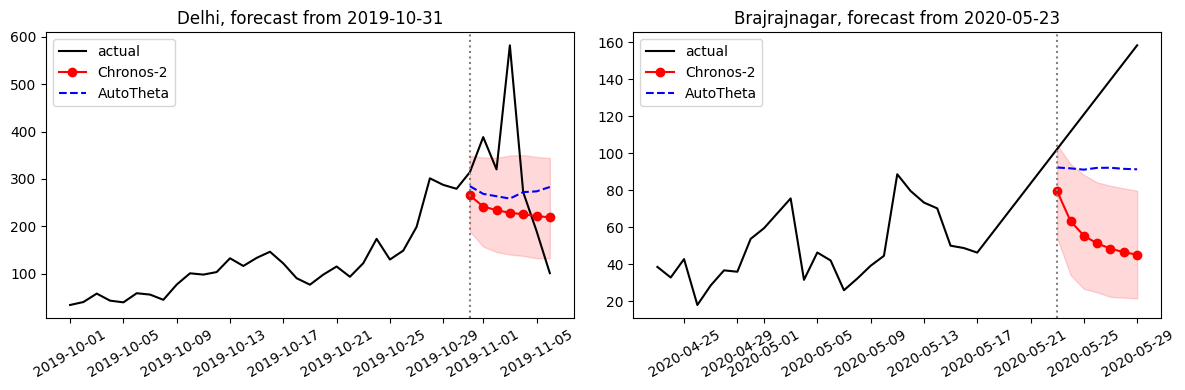

In [6]:
import matplotlib.pyplot as plt
H = 7
fc = []
for city, s in long_cities.items():
    for o in range(len(s) - 365, len(s) - H + 1, 30):
        history = s.iloc[:o]
        scale = np.mean(np.abs(history.values[7:] - history.values[:-7]))
        h = history.reset_index(); h.columns = ["timestamp", "target"]; h["id"] = city
        out = pipe.predict_df(h, prediction_length=H, id_column="id",
                              timestamp_column="timestamp", target="target", freq="D")
        truth = s.iloc[o:o+H]
        for k in range(H):
            fc.append((city, s.index[o], k+1, truth.index[k], truth.iloc[k], scale,
                       history.iloc[-1], out["predictions"].iloc[k],
                       out["0.1"].iloc[k], out["0.9"].iloc[k]))
fc = pd.DataFrame(fc, columns=["city", "origin_date", "day", "date", "truth", "scale",
                               "naive", "chronos2", "lo", "hi"])

c = cv.rename(columns={"unique_id": "city", "ds": "date", "AutoTheta": "autotheta",
                       "AutoETS": "autoets", "y": "y_check"})
fc = fc.merge(c[["city", "date", "autotheta", "autoets", "y_check"]], on=["city", "date"])
print(len(fc), "rows (expect 1344); truth matches:", np.allclose(fc["truth"], fc["y_check"]))
fc.to_csv("forecasts.csv", index=False)

# 1) Error by forecast day
for m in ["naive", "autotheta", "autoets", "chronos2"]:
    fc[m + "_mase"] = np.abs(fc["truth"] - fc[m]) / fc["scale"]
print(fc.groupby("day")[["naive_mase", "autotheta_mase", "autoets_mase", "chronos2_mase"]].mean().round(2))

# 2) Failure-case plots
cases = [("Delhi", "2019-10-31"), ("Brajrajnagar", "2020-05-23")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (city, d) in zip(axes, cases):
    s = long_cities[city]; d = pd.Timestamp(d)
    g = fc[(fc.city == city) & (fc.origin_date == d)]
    ax.plot(s.loc[d - pd.Timedelta(days=30): d + pd.Timedelta(days=6)], "k", label="actual")
    ax.plot(g["date"], g["chronos2"], "r-o", label="Chronos-2")
    ax.fill_between(g["date"], g["lo"], g["hi"], color="r", alpha=0.15)
    ax.plot(g["date"], g["autotheta"], "b--", label="AutoTheta")
    ax.axvline(d, color="gray", ls=":"); ax.set_title(f"{city}, forecast from {d.date()}")
    ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("failure_cases.png", dpi=150); plt.show()

                  mae  mase
model                      
chronos2        16.05  0.59
autotheta       18.72  0.67
naive           19.20  0.69
autoets         21.10  0.76
seasonal_naive  22.77  0.82


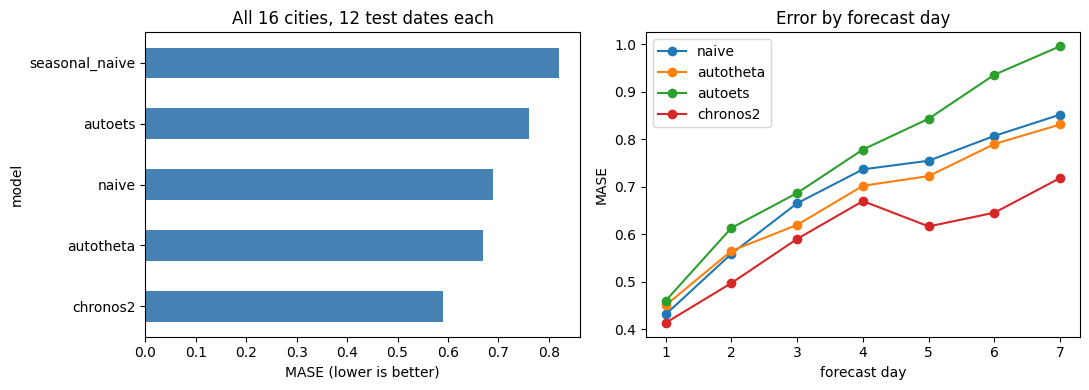

In [7]:
import matplotlib.pyplot as plt
summary = res2.groupby("model")[["mae", "mase"]].mean().round(2).sort_values("mase")
summary.to_csv("results_table.csv"); print(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
summary["mase"].plot.barh(ax=ax[0], color="steelblue")
ax[0].set_xlabel("MASE (lower is better)"); ax[0].set_title("All 16 cities, 12 test dates each")
day = fc.groupby("day")[["naive_mase", "autotheta_mase", "autoets_mase", "chronos2_mase"]].mean()
day.columns = ["naive", "autotheta", "autoets", "chronos2"]
day.plot(ax=ax[1], marker="o"); ax[1].set_xlabel("forecast day"); ax[1].set_ylabel("MASE")
ax[1].set_title("Error by forecast day")
plt.tight_layout(); plt.savefig("main_results.png", dpi=150); plt.show()

In [9]:
# which days were real measurements (not interpolated)?
obs = {}
for city, g in df.groupby("unique_id"):
    s = g.set_index("ds")["y"].asfreq("D")
    s = s.loc[s.first_valid_index():s.last_valid_index()]
    obs[city] = s.notna()

fc = pd.read_csv("forecasts.csv", parse_dates=["origin_date", "date"])
fc["observed"] = [bool(obs[c].get(d, False)) for c, d in zip(fc.city, fc.date)]
print("share of scored days that were interpolated:", round(1 - fc["observed"].mean(), 3))
print(fc.groupby("city")["observed"].apply(lambda x: round(1 - x.mean(), 2)).sort_values(ascending=False).head(6))

models = ["naive", "autotheta", "autoets", "chronos2"]
for m in models:
    fc[m + "_mase"] = np.abs(fc["truth"] - fc[m]) / fc["scale"]
cols = [m + "_mase" for m in models]

print(pd.DataFrame({"all days (current)": fc[cols].mean(),
                    "real observations only": fc[fc.observed][cols].mean()}).round(3))

t = fc[fc.observed].groupby("city")[["autotheta_mase", "chronos2_mase"]].mean()
gain = (t["autotheta_mase"] - t["chronos2_mase"]).values
rng = np.random.default_rng(0)
boots = [rng.choice(gain, len(gain)).mean() for _ in range(10000)]
print("Gain over AutoTheta:", round(gain.mean(), 3), "95% range:", np.percentile(boots, [2.5, 97.5]).round(3))

pd.DataFrame({"all_days": fc[cols].mean(), "observed_only": fc[fc.observed][cols].mean()}).to_csv("robustness.csv")

share of scored days that were interpolated: 0.025
city
Amaravati        0.15
Brajrajnagar     0.10
Talcher          0.07
Visakhapatnam    0.05
Amritsar         0.02
Delhi            0.00
Name: observed, dtype: float64
                all days (current)  real observations only
naive_mase                   0.687                   0.693
autotheta_mase               0.669                   0.674
autoets_mase                 0.759                   0.762
chronos2_mase                0.593                   0.588
Gain over AutoTheta: 0.086 95% range: [0.049 0.124]
